<a href="https://colab.research.google.com/github/dbonjd007/ds-core-projects/blob/main/time-series-analysis/your_notebook_name.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install statsmodels

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
df = pd.read_csv("Electric_Production.csv")
df.head()

,DATE,Value
0,01-01-1985,72.5052
1,02-01-1985,70.6720
2,03-01-1985,62.4502
3,04-01-1985,57.4714
4,05-01-1985,55.3151


In [ ]:
df['DATE'] = pd.to_datetime(df['DATE'])
df.head()

,DATE,Value
0,1985-01-01,72.5052
1,1985-02-01,70.6720
2,1985-03-01,62.4502
3,1985-04-01,57.4714
4,1985-05-01,55.3151


In [ ]:
df.set_index('DATE', inplace=True)
df.head()

,Value
DATE,
1985-01-01,72.5052
1985-02-01,70.6720
1985-03-01,62.4502
1985-04-01,57.4714
1985-05-01,55.3151


def create_date_features(df):
  df_new = df.copy()
  # Basic date components
  df_new["date"] = df_new.index
  df_new["day"] = df_new.index.day
  df_new["month"] = df_new.index.month
  df_new["year"] = df_new.index.year
  # Day-based Features
  df_new["day_of_week"] = df_new.index.dayofweek
  df_new["is_weekend"] = df_new["day_of_week"].isin([5,6]).astype(int)
  df_new["day_of_year"] = df_new.index.dayofyear
  df_new["day_name"] = df_new.index.day_name()
   # Week-based features
  df_new["week_of_year"] = df_new.index.isocalendar().week
  # Month-Based Features
  df_new["quarter"] = df_new.index.quarter
  df_new["month_name"] = df_new.index.month_name()
  df_new["days_in_month"] = df_new.index.days_in_month
  # Seasonal Features
  df_new["season"] = pd.cut(df_new["month"], bins=[0,3,6,9,12], labels=["Winter", "Spring", "Summer", "Fall"], include_lowest=True)
  return df_new

In [ ]:
def create_date_features(df):
  df_new = df.copy()
  # Basic date components
  df_new["date"] = df_new.index
  df_new["day"] = df_new.index.day
  df_new["month"] = df_new.index.month
  df_new["year"] = df_new.index.year
  # Day-based Features
  df_new["day_of_week"] = df_new.index.dayofweek
  df_new["is_weekend"] = df_new["day_of_week"].isin([5,6]).astype(int)
  df_new["day_of_year"] = df_new.index.dayofyear
  df_new["day_name"] = df_new.index.day_name()
   # Week-based features
  df_new["week_of_year"] = df_new.index.isocalendar().week
  # Month-Based Features
  df_new["quarter"] = df_new.index.quarter
  df_new["month_name"] = df_new.index.month_name()
  df_new["days_in_month"] = df_new.index.days_in_month
  # Seasonal Features
  df_new["season"] = pd.cut(df_new["month"], bins=[0,3,6,9,12], labels=["Winter", "Spring", "Summer", "Fall"], include_lowest=True)
  return df_new

In [ ]:
newDF = create_date_features(df)
newDF.head()

,Value,date,day,month,year,day_of_week,is_weekend,day_of_year,day_name,week_of_year,quarter,month_name,days_in_month,season
DATE,,,,,,,,,,,,,,
1985-01-01,72.5052,1985-01-01,1,1,1985,1,0,1,Tuesday,1,1,January,31,Winter
1985-02-01,70.6720,1985-02-01,1,2,1985,4,0,32,Friday,5,1,February,28,Winter
1985-03-01,62.4502,1985-03-01,1,3,1985,4,0,60,Friday,9,1,March,31,Winter
1985-04-01,57.4714,1985-04-01,1,4,1985,0,0,91,Monday,14,2,April,30,Spring
1985-05-01,55.3151,1985-05-01,1,5,1985,2,0,121,Wednesday,18,2,May,31,Spring


In [ ]:
newDF.rename(columns={'Value':'Energy Consumption'}, inplace=True)
newDF.head()

,Energy Consumption,date,day,month,year,day_of_week,is_weekend,day_of_year,day_name,week_of_year,quarter,month_name,days_in_month,season
DATE,,,,,,,,,,,,,,
1985-01-01,72.5052,1985-01-01,1,1,1985,1,0,1,Tuesday,1,1,January,31,Winter
1985-02-01,70.6720,1985-02-01,1,2,1985,4,0,32,Friday,5,1,February,28,Winter
1985-03-01,62.4502,1985-03-01,1,3,1985,4,0,60,Friday,9,1,March,31,Winter
1985-04-01,57.4714,1985-04-01,1,4,1985,0,0,91,Monday,14,2,April,30,Spring
1985-05-01,55.3151,1985-05-01,1,5,1985,2,0,121,Wednesday,18,2,May,31,Spring


<Axes: xlabel='DATE'>

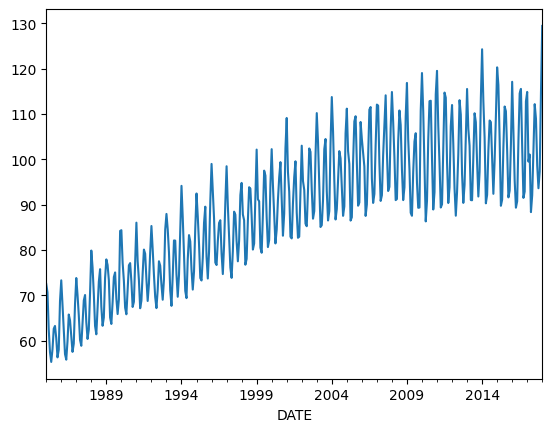

In [ ]:
newDF['Energy Consumption'].plot()

<Axes: xlabel='DATE'>

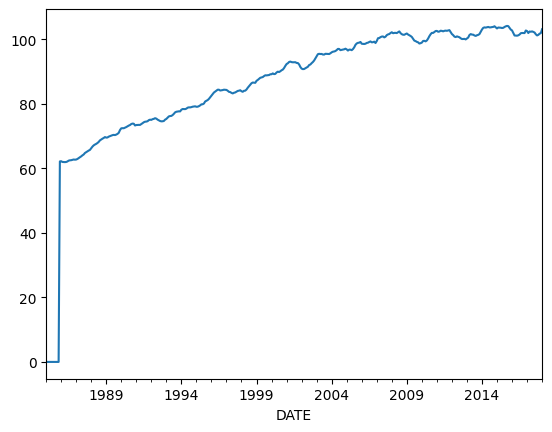

In [ ]:
newDF['Energy Consumption'].rolling(window=12).mean().fillna(0).plot()

<Axes: xlabel='year'>

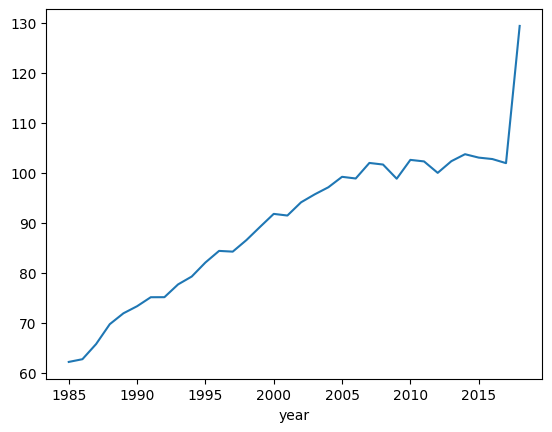

In [ ]:
newDF.groupby(["year"])["Energy Consumption"].mean().plot()

<Axes: xlabel='season'>

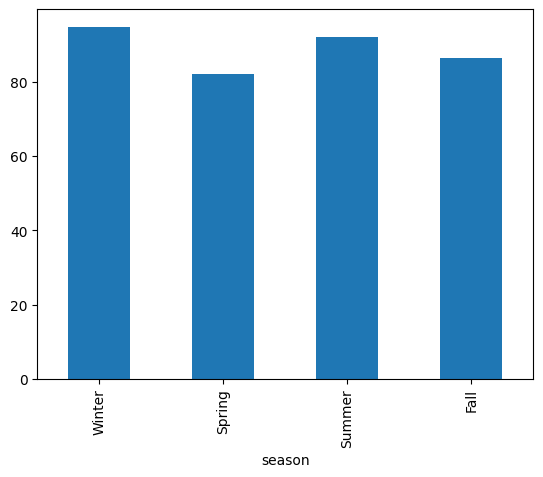

In [ ]:
newDF.groupby(['season'], observed=True)['Energy Consumption'].mean().plot(kind="bar")

<Axes: xlabel='month'>

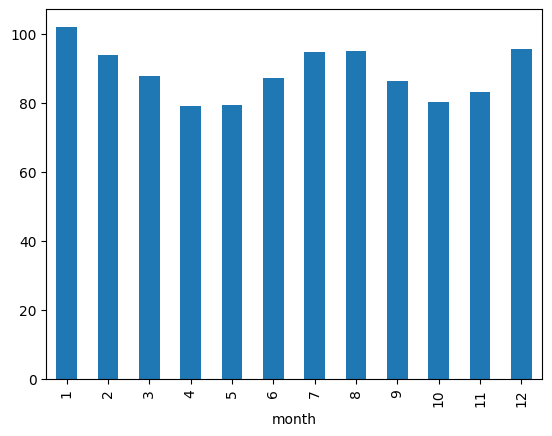

In [ ]:
newDF.groupby(['month'])['Energy Consumption'].mean().plot(kind="bar")

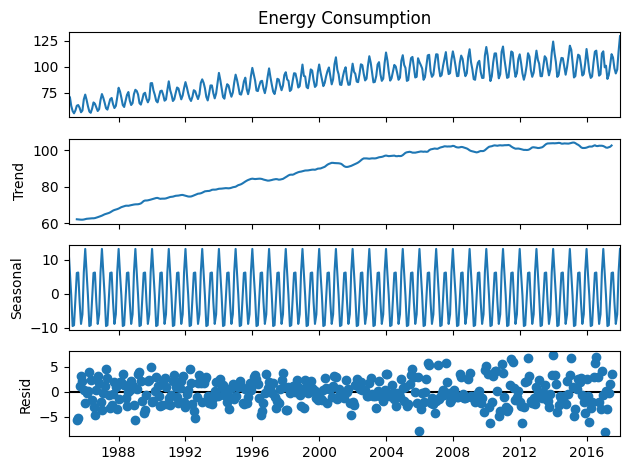

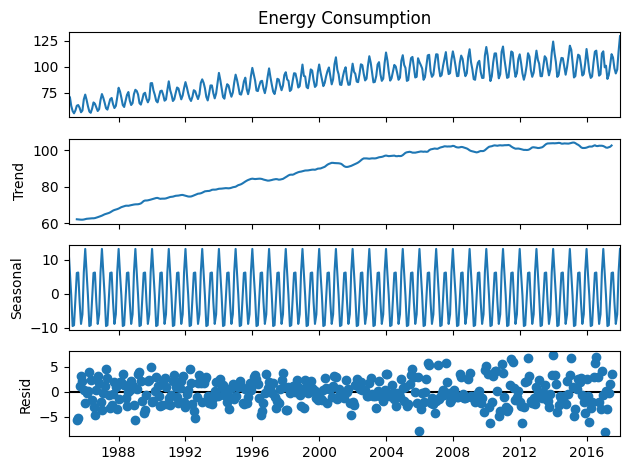

In [ ]:
season = seasonal_decompose(newDF['Energy Consumption'], model='additive', period=12)
season.plot()

<Axes: xlabel='DATE'>

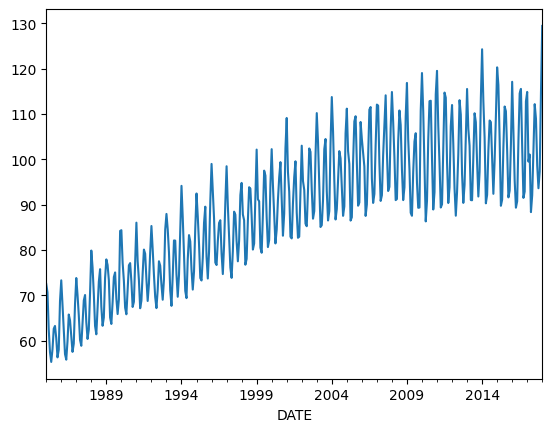

In [ ]:
season.observed.plot()

<Axes: xlabel='DATE'>

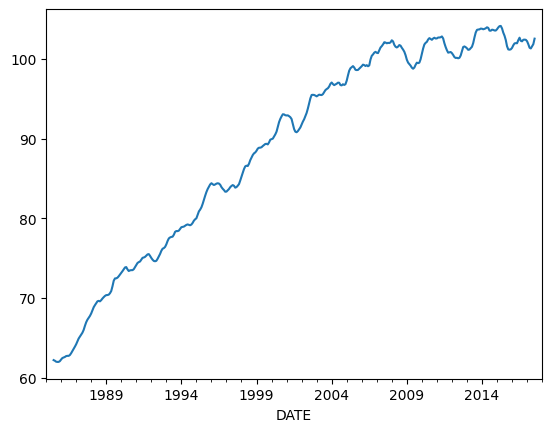

In [ ]:
season.trend.plot()

<Axes: xlabel='DATE'>

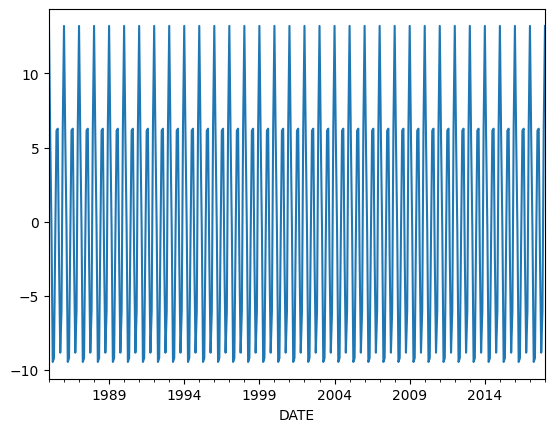

In [ ]:
season.seasonal.plot()